# P5: Deteksi Tepi (SIMUTEH)
Bagian 1 (gradien dan operator tepi) dan Bagian 2 (Canny dan keputusan). Jalankan dari folder `notebook/` dengan *Restart & Run All*.

## Bagian 1. Gradien Citra dan Operator Tepi
**Langkah 1.1 (lembar hitung manual, tulis tangan)**: tidak ada kode, kerjakan di kertas lalu lampirkan.

### Kode 1.1 Persiapan: modul, data, praproses, dan tepi acuan

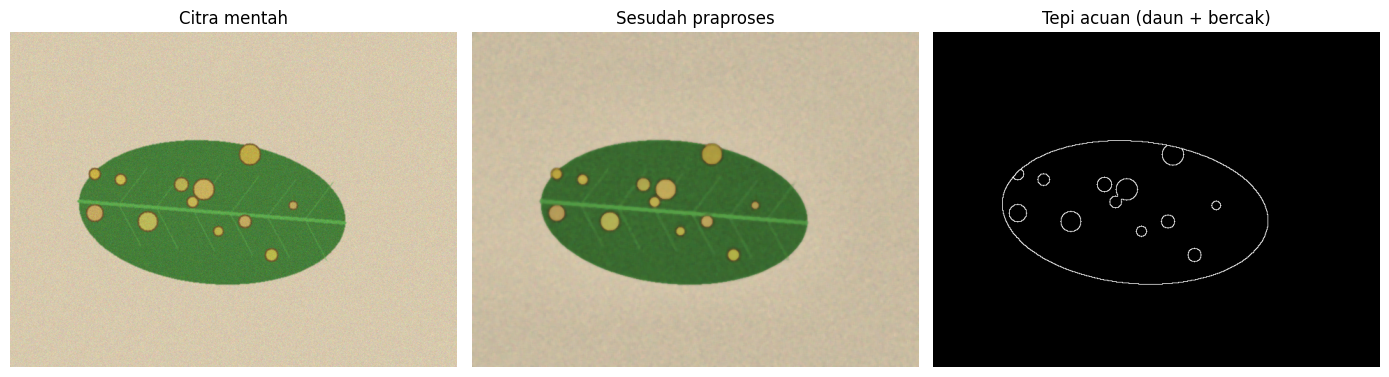

In [1]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

### Kode 1.2 Gradien Sobel manual: Gx, Gy, magnitudo, dan arah

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 514.7


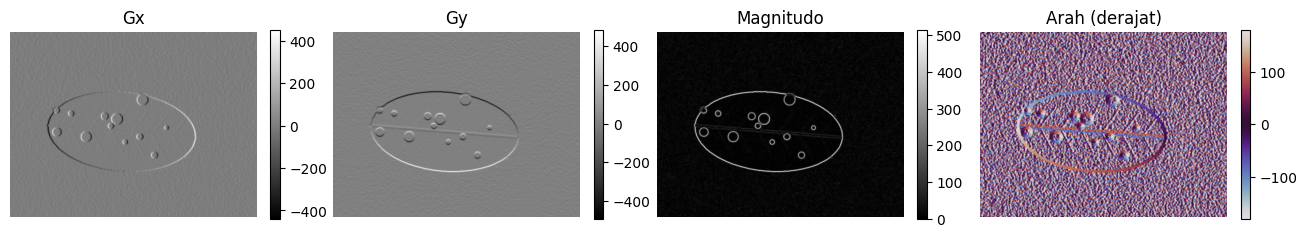

In [2]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.show()

### Kode 1.3 Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya

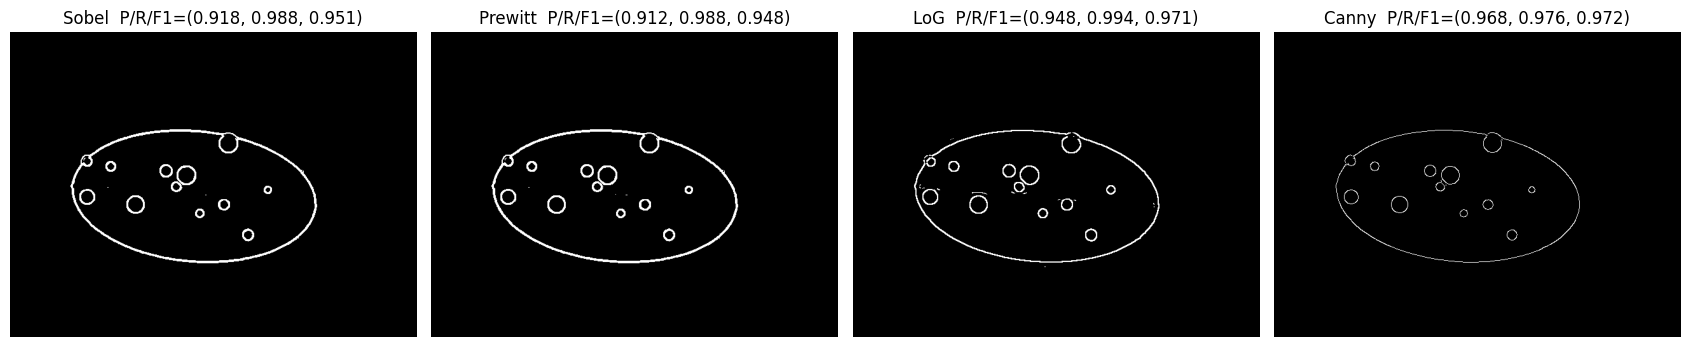

In [3]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))

### Kode 1.4 Tabel presisi, recall, dan F1 tepi (bahan Tabel 6)

In [4]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.736  0.754  0.743
                LoG      0.632  0.998  0.768
                Prewitt  0.805  0.953  0.859
                Sobel    0.778  0.962  0.846
          R     Canny    0.984  0.970  0.975
                LoG      0.875  0.998  0.919
                Prewitt  0.642  0.995  0.736
                Sobel    0.580  0.995  0.682
praproses Gray  Canny    0.891  0.895  0.890
                LoG      0.649  0.997  0.782
                Prewitt  0.875  0.965  0.913
                Sobel    0.873  0.969  0.914
          R     Canny    0.983  0.985  0.984
                LoG      0.911  0.997  0.948
                Prewitt  0.938  0.994  0.964
                Sobel    0.941  0.994  0.966


### Langkah 1.5 (Kerjakan sendiri) Grafik F1 per kondisi cahaya

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
normal          0.959    0.956  0.986  0.985
gelap           0.935    0.932  0.976  0.986
terang          0.977    0.977  0.927  0.986
kontras_rendah  0.990    0.989  0.880  0.983
bayangan        0.971    0.969  0.972  0.981


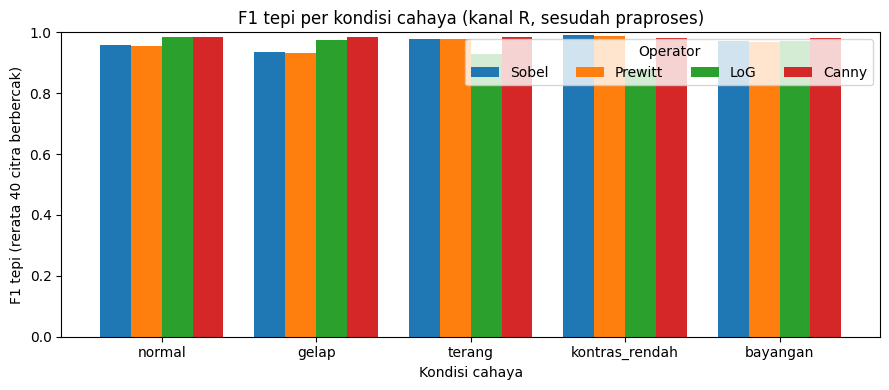

In [5]:
# Langkah 1.5 (Kerjakan sendiri): grafik batang F1 per kondisi cahaya, kanal R sesudah praproses
urut = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
r = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
f1_kondisi = (r.pivot_table(index="kondisi", columns="metode", values="F1", aggfunc="mean")
                .reindex(urut)[["Sobel", "Prewitt", "LoG", "Canny"]])
print(f1_kondisi.round(3))

ax = f1_kondisi.plot(kind="bar", figsize=(9, 4), width=0.8)
ax.set_ylabel("F1 tepi (rerata 40 citra berbercak)"); ax.set_xlabel("Kondisi cahaya")
ax.set_title("F1 tepi per kondisi cahaya (kanal R, sesudah praproses)")
ax.set_ylim(0, 1); plt.xticks(rotation=0); plt.legend(title="Operator", ncol=4)
plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 2. Algoritma Canny dan Keputusan Pemakaian Tepi
**Langkah 2.1 (lembar hitung manual, tulis tangan)**: NMS dan hysteresis.

### Kode 2.1 Eksperimen sigma dan ambang Canny (bahan Tabel 7)

In [6]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]           # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))
canny.to_csv("../hasil/p5_canny_sigma_ambang.csv", index=False)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.981  0.988  0.984     0.930
      30/90    0.564  0.993  0.675     0.960
      50/150   0.950  0.992  0.970     0.956
1.0   100/200  0.915  0.868  0.877     0.760
      30/90    0.917  0.992  0.949     0.954
      50/150   0.980  0.987  0.983     0.895
2.0   100/200  0.796  0.712  0.739     0.482
      30/90    0.983  0.985  0.984     0.897
      50/150   0.791  0.785  0.788     0.700
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.962   0.899
      30/90    0.973   0.946
      50/150   0.970   0.941
1.0   100/200  0.787   0.733
      30/90    0.972   0.935
      50/150   0.965   0.824
2.0   100/200  0.582   0.383
      30/90    0.941   0.854
      50/150   0.752   0.649


### Kode 2.2 Ambang Canny otomatis berbasis median

In [7]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))
auto.to_csv("../hasil/p5_ambang_otomatis.csv", index=False)

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.864  0.902           0.529   0.979   0.970
      tetap 30/90     0.936  0.918           0.790   0.893   0.910
R     otomatis        0.979  0.981           0.975   0.985   0.992
      tetap 30/90     0.981  0.986           0.983   0.985   0.986
kanal  kondisi       
Gray   bayangan          114.1
       gelap             141.8
       kontras_rendah    155.6
       normal            181.5
       terang            208.0
R      bayangan          122.0
       gelap             157.9
       kontras_rendah    158.2
       normal            191.4
       terang            213.5
Name: median, dtype: float64


### Langkah 2.4 (Kerjakan sendiri) `canny_persentil`

In [8]:
# Langkah 2.4 (Kerjakan sendiri): ambang Canny dari persentil magnitudo gradien
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    h = cv2.GaussianBlur(g, (0, 0), sigma)                                    # (1) haluskan
    hf = h.astype(np.float32)
    mag = np.hypot(cv2.Sobel(hf, cv2.CV_32F, 1, 0), cv2.Sobel(hf, cv2.CV_32F, 0, 1))   # (2) magnitudo Sobel
    hi = float(np.percentile(mag, q))                                         # (3) ambang atas = persentil ke-q
    lo = rasio * hi                                                           #     ambang bawah = rasio x atas
    return cv2.Canny(h, lo, hi, L2gradient=True)                              # (4) Canny

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, f"persentil {q}", skor_tepi(canny_persentil(g, q), ac)[2]])
per = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
semua = pd.concat([per, auto[["kondisi", "kanal", "ambang", "F1"]]])     # gabung dengan Kode 2.2
tabel_ambang = semua.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3)
print(tabel_ambang)
tabel_ambang.to_csv("../hasil/p5_canny_persentil.csv")

kondisi             bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                       
Gray  otomatis         0.864  0.902           0.529   0.979   0.970
      persentil 90     0.094  0.103           0.064   0.112   0.086
      persentil 95     0.673  0.700           0.507   0.720   0.636
      persentil 98     0.815  0.909           0.856   0.929   0.869
      tetap 30/90      0.936  0.918           0.790   0.893   0.910
R     otomatis         0.979  0.981           0.975   0.985   0.992
      persentil 90     0.111  0.100           0.078   0.112   0.101
      persentil 95     0.590  0.506           0.453   0.689   0.663
      persentil 98     0.984  0.989           0.988   0.988   0.990
      tetap 30/90      0.981  0.986           0.983   0.985   0.986


### Kode 2.3 Tepi palsu di bagian dalam daun sehat

kanal            Gray    R
kondisi                   
bayangan        251.0  0.0
gelap           279.8  0.0
kontras_rendah    0.0  0.0
normal          323.5  0.0
terang            0.0  0.0


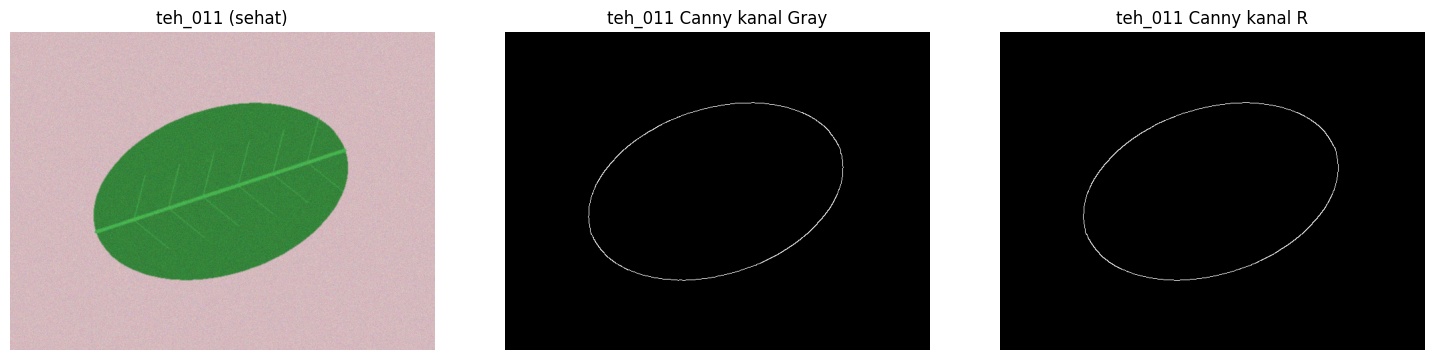

In [9]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0     # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))

### Langkah 2.6 (Kerjakan sendiri) Tabel 8: keputusan pemakaian deteksi tepi
Isi tabel di laporan setelah membaca Tabel 6, Tabel 7, dan hasil Kode 2.3. Kerangka isian:

| Keperluan | Dipakai? | Operator dan parameter | Bukti |
|---|---|---|---|
| Menemukan batas daun | | | |
| Menemukan batas bercak | | | |
| Mengisi wilayah bercak (segmentasi) | | | |
| Fitur bentuk bercak (P9) | | | |

### Langkah 2.7 Checkpoint
Commit seluruh pekerjaan P5, lalu beri tag: `git tag v0.2-tepi` dan `git push --tags`.